Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")

Load the Dataset

In [2]:

df = pd.read_csv('student_performance.csv')

print("Dataset loaded successfully.")


Dataset loaded successfully.


Understand the Dataset

In [3]:
print("----- DATASET OVERVIEW -----")

print("\nFirst 5 Rows:")
display(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

----- DATASET OVERVIEW -----

First 5 Rows:


,student_id,study_hours,attendance,previous_score,final_score
0,1,2.0,65.0,55.0,58
1,2,3.0,70.0,60.0,62
2,3,4.0,75.0,65.0,68
3,4,5.0,80.0,70.0,74
4,5,6.0,85.0,75.0,80



Dataset Shape:
(20, 5)

Column Names:
['student_id', 'study_hours', 'attendance', 'previous_score', 'final_score']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   student_id      20 non-null     int64  
 1   study_hours     19 non-null     float64
 2   attendance      19 non-null     float64
 3   previous_score  19 non-null     float64
 4   final_score     20 non-null     int64  
dtypes: float64(3), int64(2)
memory usage: 932.0 bytes

Statistical Summary:


,student_id,study_hours,attendance,previous_score,final_score
count,20.00000,19.000000,19.000000,19.000000,20.000000
mean,10.50000,5.210526,79.947368,71.210526,78.100000
std,5.91608,2.274959,10.437505,12.899522,20.455086
min,1.00000,2.000000,60.000000,50.000000,55.000000
25%,5.75000,3.500000,72.500000,61.000000,66.250000
50%,10.50000,5.000000,80.000000,70.000000,75.000000
75%,15.25000,6.500000,87.000000,80.000000,84.250000
max,20.00000,10.000000,98.000000,95.000000,150.000000


Check and Handle Missing Values

In [4]:
print("----- MISSING VALUES -----")

print("Missing values per column:")
display(df.isnull().sum())

print("\nMissing value percentage:")
display((df.isnull().mean() * 100).round(2))

# Fill missing numerical values with each column's median
numeric_cols = df.select_dtypes(include=np.number).columns

for col in numeric_cols:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].median())

print("\nMissing values after treatment:")
display(df.isnull().sum())

----- MISSING VALUES -----
Missing values per column:


student_id        0
study_hours       1
attendance        1
previous_score    1
final_score       0
dtype: int64


Missing value percentage:


student_id        0.0
study_hours       5.0
attendance        5.0
previous_score    5.0
final_score       0.0
dtype: float64


Missing values after treatment:


student_id        0
study_hours       0
attendance        0
previous_score    0
final_score       0
dtype: int64

Check Duplicate Records

In [5]:
print("----- DUPLICATES -----")

print("Duplicate rows:", df.duplicated().sum())

df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

----- DUPLICATES -----
Duplicate rows: 0
Shape after removing duplicates: (20, 5)


Explore Data Distributions

----- DISTRIBUTION ANALYSIS -----


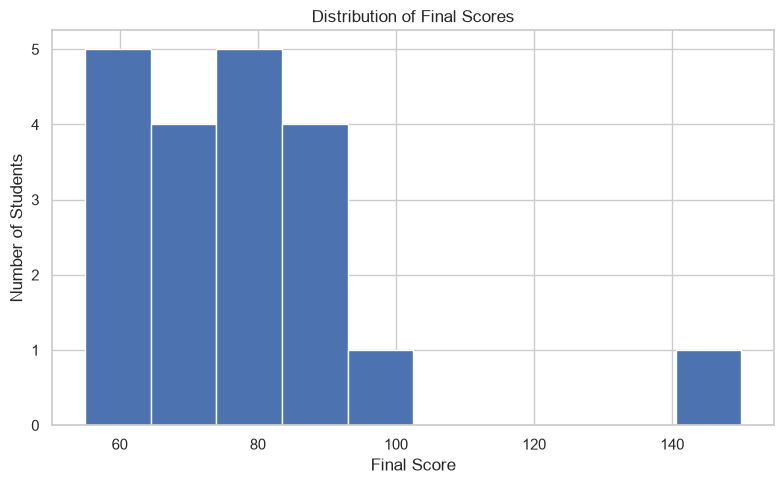

In [6]:
print("----- DISTRIBUTION ANALYSIS -----")



df["final_score"].hist(bins=10, figsize=(8, 5))

plt.title("Distribution of Final Scores")
plt.xlabel("Final Score")
plt.ylabel("Number of Students")
plt.tight_layout()

plt.savefig("marks_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

Correlation Analysis

----- CORRELATION MATRIX -----


,student_id,study_hours,attendance,previous_score,final_score
student_id,1.00,0.37,0.31,0.35,0.40
study_hours,0.37,1.00,0.89,0.98,0.90
attendance,0.31,0.89,1.00,0.92,0.81
previous_score,0.35,0.98,0.92,1.00,0.87
final_score,0.40,0.90,0.81,0.87,1.00


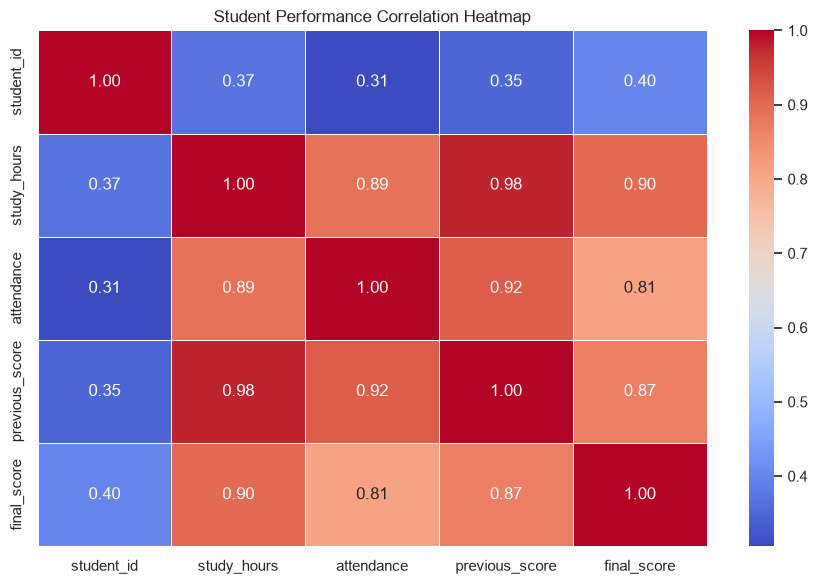

In [7]:
print("----- CORRELATION MATRIX -----")

correlation = df.corr(numeric_only=True)

display(correlation.round(2))

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Student Performance Correlation Heatmap")
plt.tight_layout()

plt.savefig("correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

Detect Potential Outliers Using IQR

In [8]:
print("----- OUTLIER DETECTION -----")

outlier_cols = [
    "study_hours",
    "attendance",
    "previous_score",
    "final_score"
]

for col in outlier_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    print(f"\nColumn: {col}")
    print("Lower Bound:", lower_bound)
    print("Upper Bound:", upper_bound)
    print("Outlier Count:", len(outliers))

    if not outliers.empty:
        display(outliers[["student_id", col]])

----- OUTLIER DETECTION -----

Column: study_hours
Lower Bound: 0.0
Upper Bound: 10.0
Outlier Count: 0

Column: attendance
Lower Bound: 52.125
Upper Bound: 107.125
Outlier Count: 0

Column: previous_score
Lower Bound: 33.75
Upper Bound: 107.75
Outlier Count: 0

Column: final_score
Lower Bound: 39.25
Upper Bound: 111.25
Outlier Count: 1


,student_id,final_score
17,18,150


Visualize Potential Outliers

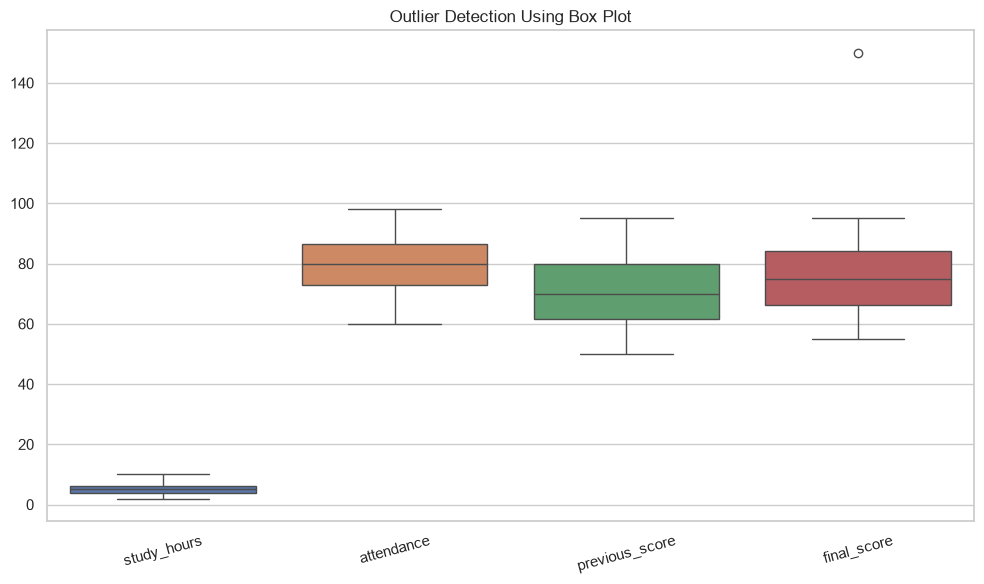

In [9]:
plt.figure(figsize=(10, 6))

sns.boxplot(data=df[outlier_cols])

plt.title("Outlier Detection Using Box Plot")
plt.xticks(rotation=15)
plt.tight_layout()

plt.savefig("outlier_boxplot.png", dpi=150, bbox_inches="tight")
plt.show()

Final EDA Summary

In [10]:
print("----- FINAL EDA SUMMARY -----")

print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])
print("Duplicate Rows:", df.duplicated().sum())
print("Missing Values:", df.isnull().sum().sum())

print("\nEDA Completed Successfully!")

----- FINAL EDA SUMMARY -----
Total Rows: 20
Total Columns: 5
Duplicate Rows: 0
Missing Values: 0

EDA Completed Successfully!
